# 01: Exploring the Kaggle men's data

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path("../data/raw/march-machine-learning-mania-2026")

teams = pd.read_csv(DATA / "MTeams.csv")
seasons = pd.read_csv(DATA / "MSeasons.csv")
games = pd.read_csv(DATA / "MRegularSeasonDetailedResults.csv")

## Basics
Understanding the basics of the data

In [2]:
print(f"Seasons rows: {seasons.shape[0]}. Columns: {seasons.shape[1]}")
print(f"Earliest Season: {seasons['Season'].min()}. Latest Season: {seasons['Season'].max()}")
print(f"Games rows: {games.shape[0]}. Columns: {games.shape[1]}")
print(f"Earliest Box Scores: {games['Season'].min()}. Latest Box Scores: {games['Season'].max()}")

Seasons rows: 42. Columns: 6
Earliest Season: 1985. Latest Season: 2026
Games rows: 124529. Columns: 34
Earliest Box Scores: 2003. Latest Box Scores: 2026


In [13]:
print(games.head(1))
w_team = teams[teams['TeamID'] == games['WTeamID'].values[0]]
l_team = teams[teams['TeamID'] == games['LTeamID'].values[0]]
print(f"Winning Team: {w_team['TeamName'].values[0]}. Losing Team: {l_team['TeamName'].values[0]}")
print(f"Score: {games['WScore'].values[0]} - {games['LScore'].values[0]}")
print(f"Winning fg%: {games['WFGM'].values[0]}/{games['WFGA'].values[0]} = {games['WFGM'].values[0]/games['WFGA'].values[0]:.2%}")
if(games['WLoc'].values[0] == 'H'):
    print(f"Location: {w_team['TeamName'].values[0]} home")
elif(games['WLoc'].values[0] == 'A'):
    print(f"Location: {l_team['TeamName'].values[0]} home")
else:
    print("Location: Neutral Site")

   Season  DayNum  WTeamID  WScore  LTeamID  LScore WLoc  NumOT  WFGM  WFGA  \
0    2003      10     1104      68     1328      62    N      0    27    58   

   ...  LFGA3  LFTM  LFTA  LOR  LDR  LAst  LTO  LStl  LBlk  LPF  
0  ...     10    16    22   10   22     8   18     9     2   20  

[1 rows x 34 columns]
Winning Team: Alabama. Losing Team: Oklahoma
Score: 68 - 62
Winning fg%: 27/58 = 46.55%
Location: Neutral Site


### Notes
There are 42 seasons each having 6 columns storing the year, the date of day zero and the regions order for tournament structure. The earliest season tracked is 1985 and tracks data through the 2026 season. However, detailed box scores are only tracked back to 2003.

The games track all box score related data, using W to track winners data and L to track losers data. The location is given from the percpective of the winning team. This is in the form of H/A/N representing Home/Away/Neutral. The first game of the 2003 season in the data is an Alabama win against Oklahoma at a neutral site. The final score was 68 - 62 where Alabama shot 46.55% from the field.

## Model Problems
The data structured as is will create complications with training. The model will train to say the winning team wins because it is labeled as the winner. There also isn't a way to organize by team and their opponents. We need to restructure the raw data into one row per team per game.

In [4]:
w_rename = {}
for col in games.columns:
    if col == 'WLoc':
        continue
    if col.startswith('W'):
        w_rename[col] = col[1:]
    elif col.startswith('L'):
        w_rename[col] = "Opp" + col[1:]
winners = games.rename(columns=w_rename).drop(columns=['WLoc'])
winners['Loc'] = games['WLoc']
winners['Win'] = 1

l_rename = {}
for col in games.columns:
    if col == 'WLoc':
        continue
    if col.startswith('L'):
        l_rename[col] = col[1:]
    elif col.startswith('W'):
        l_rename[col] = "Opp" + col[1:]

losers = games.rename(columns=l_rename).drop(columns=['WLoc'])
losers['Loc'] = games['WLoc'].map({'H': 'A', 'A': 'H', 'N': 'N'})
losers['Win'] = 0

team_games = pd.concat([winners, losers], ignore_index=True)
print(f"Original games shape: {games.shape}")
print(f"Team games shape: {team_games.shape}")

Original games shape: (124529, 34)
Team games shape: (249058, 35)


### Convert DayNum to readable dates

In [5]:
seasons['DayZero'] = pd.to_datetime(seasons['DayZero'], format="%m/%d/%Y")
seasons.dtypes

Season              int64
DayZero    datetime64[us]
RegionW               str
RegionX               str
RegionY               str
RegionZ               str
dtype: object

In [6]:
team_games = team_games.merge(seasons[['Season', 'DayZero']], on='Season', how='left')
team_games['Date'] = pd.to_timedelta(team_games['DayNum'], unit='D') + team_games['DayZero']
print(team_games["Date"].isna().sum())                           # should be 0
print(team_games.loc[team_games["Season"] == 2026, "Date"].agg(["min", "max"]))
print(team_games.loc[team_games["Season"] == 2003, "Date"].agg(["min", "max"]))

0
min   2025-11-03
max   2026-03-15
Name: Date, dtype: datetime64[us]
min   2002-11-14
max   2003-03-16
Name: Date, dtype: datetime64[us]


### Computing Possessions

In [7]:
team_games['Possessions'] = ((team_games['FGA'] - team_games['OR'] + team_games['TO'] + 0.475 * team_games['FTA']) + (team_games['OppFGA'] - team_games['OppOR'] + team_games['OppTO'] + 0.475 * team_games['OppFTA']))/2
first_game = team_games[(team_games["Season"] == 2003) &
                        (team_games["DayNum"] == 10) &
                        (team_games["TeamID"].isin([1104, 1328]))]
first_game[["TeamID", "OppTeamID", "Score", "Possessions"]]
print (f"Possessions: {first_game['Possessions'].values[0]:.2f}")

Possessions: 73.50


### Notes
Restructuring the data this way allows for training to not be biased for the position of the team in the games columns. This makes it possible to compute features from each teams prior games, which will prevent leakage. The possessions value is very important for future calculations. A team who scores 80 points in 80 possessions is not as effective as a team that scores 70 points in 60 possessions. This is why we will eventually use points per 100 possessions.

## Sanity Checks

### Missing Values or Duplicate Games

In [11]:
print(f"Number of missing values: {games.isnull().sum().sum()}")
print(f"Number of duplicate games: {games.duplicated(subset=["Season", "DayNum", "WTeamID", "LTeamID"]).sum()}")

Number of missing values: 0
Number of duplicate games: 0


### Average Margin of Victory

<Axes: title={'center': 'Average margin of victory by season'}, xlabel='Season', ylabel='Points'>

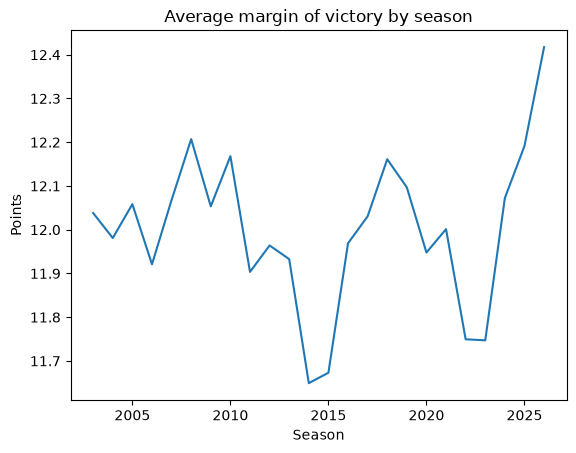

In [ ]:
winners_average = games.groupby(['Season'])['WScore'].mean()
losers_average = games.groupby(['Season'])['LScore'].mean()
margins = winners_average - losers_average
margins.plot(title="Average margin of victory by season", xlabel="Season", ylabel="Points")

### Percent of Winners at Home


Home win percentage: 65.48%
Home team average margin of victory: 5.61


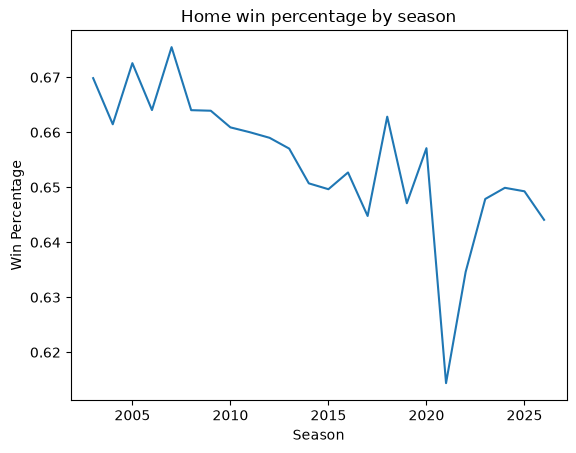

In [10]:
home_teams = team_games[team_games['Loc'] == 'H']
home_win_percentage = home_teams['Win'].mean()
season_home_win_percentage = home_teams.groupby('Season')['Win'].mean()
season_home_win_percentage.plot(title="Home win percentage by season", xlabel="Season", ylabel="Win Percentage")
print(f"Home win percentage: {home_win_percentage:.2%}")
home_team_average_margin = home_teams['Score'].mean() - home_teams['OppScore'].mean()
print(f"Home team average margin of victory: {home_team_average_margin:.2f}")

### Notes
No missing values or duplicates is a good sign, indicating there are no problems with the data. The average margin of victory is stable at abount 12 points every year. The interesting thing to note is the home in percentage per seaseon. There is a large drop in 2021, this is most likely due to the covid season having few or no fans at the stadiums. While this drop indicates that home court is a real advantage, the 5.61 margin of victory overstates the actual impact of a home court. Strong teams often pay for weaker teams to come to their stadium early in the season to boost their record. This skews the data and the real home court margin should sit around 3. to account for this, I will instead focus on key matchups and in-conference games when calculating home court advantage.

## Key Takeaways

* There is a lot of data to digest, but there are many functions to make this much more managable
* The raw data is structered in a way not suited for our model, so we need ro reform it to have a row per team per game
* We need to calculate statistics per 100 possessions instead of per game to even out the data
* Sanity check shows the data is complete and accurate
* While home court advantage is a real thing, it can be overstated through buy games